## X-Ray Abnormality Detection | DenseNet-20, pretrained on ImageNet

> **Antonopoulos Ilias** ( *p3352004* ) <br />
> **Ndoja Silva** ( *p3352017* ) <br />
> **MSc in Data Science, AUEB**

## Table of Contents

- [Data Loading](#Data-Loading)
 * [Create a tensorflow input pipeline for the training data](#Create-a-tensorflow-input-pipeline-for-the-training-data)
- [DenseNet201 architecture, pretrained on ImageNet](#DenseNet201-architecture,-pretrained-on-ImageNet)

In [1]:
# Gerekli kütüphaneleri ve modülleri içe aktarır
import os
import pathlib
import random
import re
from glob import glob

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import cohen_kappa_score
from sklearn.utils import shuffle

from utils import (
    clean_up,
    F1Score,
    inspect_df,
    plot_metrics,
)

# Grafiklerin koyu arka planlı bir stil kullanarak çizilmesini sağlar
plt.style.use("dark_background")


In [2]:
print(tf.__version__)

2.16.1


In [3]:
# Kullanılabilir GPU sayısını yazdırır
print("Num GPUs Available: ", len(tf.config.list_physical_devices("GPU")))


Num GPUs Available:  0


In [4]:
# GPU'ları listeler
gpus = tf.config.experimental.list_physical_devices("GPU")

# Bellek büyümesini etkinleştirir
try:
    tf.config.experimental.set_memory_growth(gpus[0], True)
except IndexError:
    # Eğer sistemde GPU bulunmuyorsa, GPU belleğini kısıtlamak mümkün olmaz ve bu durumu gösterir
    print("GPU belleğini kısıtlama yapılamıyor, eğer sistemde GPU bulunmuyorsa. Göz ardı ediliyor...")
    pass


GPU belleğini kısıtlama yapılamıyor, eğer sistemde GPU bulunmuyorsa. Göz ardı ediliyor...


In [5]:
# Rastgelelik kontrolünü sağlamak için bir tohum (seed) ayarlar
SEED = 99910123

# Python hash tohumunu ayarlar
os.environ["PYTHONHASHSEED"] = str(SEED)

# Rastgele modülü için tohumu ayarlar
random.seed(SEED)

# TensorFlow rastgele tohumunu ayarlar
tf.random.set_seed(SEED)

# NumPy rastgele tohumunu ayarlar
np.random.seed(SEED)


### Data Loading

In [6]:
DATASET_DIR = "../data/MURA-v1.1/"

In [7]:
random.choices(glob(os.path.join(DATASET_DIR, "*", "*", "*", "*", "*.png")), k=10)

['../data/MURA-v1.1\\train\\XR_HAND\\patient10850\\study1_negative\\image1.png',
 '../data/MURA-v1.1\\train\\XR_ELBOW\\patient05367\\study1_positive\\image2.png',
 '../data/MURA-v1.1\\valid\\XR_ELBOW\\patient11342\\study1_positive\\image1.png',
 '../data/MURA-v1.1\\train\\XR_HAND\\patient03039\\study1_negative\\image3.png',
 '../data/MURA-v1.1\\train\\XR_ELBOW\\patient05051\\study1_positive\\image2.png',
 '../data/MURA-v1.1\\train\\XR_HAND\\patient11016\\study1_negative\\image2.png',
 '../data/MURA-v1.1\\train\\XR_ELBOW\\patient05373\\study1_positive\\image2.png',
 '../data/MURA-v1.1\\train\\XR_HAND\\patient10671\\study1_negative\\image1.png',
 '../data/MURA-v1.1\\train\\XR_ELBOW\\patient01475\\study1_negative\\image3.png',
 '../data/MURA-v1.1\\train\\XR_HAND\\patient02699\\study1_negative\\image3.png']

So, the data structure is the following:

```

└─train {data subset}
│   └───XR_ELBOW {study type}
│       │  └───patient00011 {patient}
│       │         └───study1_negative {study with label}
│       │               └───image1.png {view}
│       │               └───image2.png 
│       │               └───image3.png 
                        └───...
   ...
   

└─valid {data subset}
│   └───XR_HUMERUS {study type}
│       │  └───patient11216 {patient}
│       │         └───study1_negative {study with label}
│       │               └───image1.png {view}
│       │               └───image2.png 
                        └───...
```

In [8]:
# Veri setindeki PNG uzantılı resimlerin toplam sayısını hesaplar
image_count = len(list(pathlib.Path(DATASET_DIR).glob("*/*/*/*/*.png")))

# Bulunan PNG resimlerin sayısını yazdırır
print(f"Toplam PNG resmi bulunan dizin <{DATASET_DIR}>: {image_count}")


Toplam PNG resmi bulunan dizin <../data/MURA-v1.1/>: 11399


We will start by creating a tabular form of the training data (with no actual image files), in order to quickly analyze them. A proper data loader (of the actual image files) will be implemented after that, in a tensorflow-friendly manner.

In [9]:
# Eğitim görüntü yollarını içeren bir CSV dosyasını okur
train_image_paths = pd.read_csv(
    os.path.join(DATASET_DIR, "train_image_paths.csv"),
    names=["image_path"],
    header=None,
    index_col=False,
)

# Veri çerçevesini inceleyerek başlık, ilk beş satır ve özet bilgilerini yazdırır
inspect_df(train_image_paths)


şekil: (36808, 1)


,image_path
0,MURA-v1.1/train/XR_SHOULDER/patient00001/study...
1,MURA-v1.1/train/XR_SHOULDER/patient00001/study...
2,MURA-v1.1/train/XR_SHOULDER/patient00001/study...
3,MURA-v1.1/train/XR_SHOULDER/patient00002/study...
4,MURA-v1.1/train/XR_SHOULDER/patient00002/study...


In [10]:
# Görüntü yollarını ../data/ dizinine göre günceller
train_image_paths["image_path"] = train_image_paths["image_path"].map(
    lambda x: os.path.join("../data/", x)
)

# Görüntü yollarından çalışma tipini çıkarır
train_image_paths["study_type"] = train_image_paths["image_path"].map(
    lambda x: x.split("/")[4]
)

# Görüntü yollarından hastayı çıkarır
train_image_paths["patient"] = train_image_paths["image_path"].map(
    lambda x: x.split("/")[5]
)

# Görüntü yollarından çalışmayı çıkarır
train_image_paths["study"] = train_image_paths["image_path"].map(
    lambda x: x.split("/")[6]
)

# Görüntü yollarındaki resim dosyası adını kaldırır
train_image_paths["study_path"] = train_image_paths["image_path"].map(
    lambda x: re.sub(r"image\d+.png", "", x)
)


In [11]:
inspect_df(train_image_paths)

şekil: (36808, 5)


,image_path,study_type,patient,study,study_path
0,../data/MURA-v1.1/train/XR_SHOULDER/patient000...,XR_SHOULDER,patient00001,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient000...
1,../data/MURA-v1.1/train/XR_SHOULDER/patient000...,XR_SHOULDER,patient00001,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient000...
2,../data/MURA-v1.1/train/XR_SHOULDER/patient000...,XR_SHOULDER,patient00001,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient000...
3,../data/MURA-v1.1/train/XR_SHOULDER/patient000...,XR_SHOULDER,patient00002,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient000...
4,../data/MURA-v1.1/train/XR_SHOULDER/patient000...,XR_SHOULDER,patient00002,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient000...


In [12]:
# Eğitim veri setindeki etiketlenmiş çalışmaları içeren bir CSV dosyasını okur
train_labeled_studies = pd.read_csv(
    os.path.join(DATASET_DIR, "train_labeled_studies.csv"),
    names=["study_path", "label"],
    header=None,
    index_col=False,
)

# Veri çerçevesini inceleyerek başlık, ilk beş satır ve özet bilgilerini yazdırır
inspect_df(train_labeled_studies)


şekil: (13457, 2)


,study_path,label
0,MURA-v1.1/train/XR_SHOULDER/patient00001/study...,1
1,MURA-v1.1/train/XR_SHOULDER/patient00002/study...,1
2,MURA-v1.1/train/XR_SHOULDER/patient00003/study...,1
3,MURA-v1.1/train/XR_SHOULDER/patient00004/study...,1
4,MURA-v1.1/train/XR_SHOULDER/patient00005/study...,1


In [13]:
# Etiketlenmiş çalışma yollarını ../data/ dizinine göre günceller
train_labeled_studies["study_path"] = train_labeled_studies["study_path"].map(
    lambda x: os.path.join("../data/", x)
)

# Etiketleri stringe dönüştürür
train_labeled_studies["label"] = train_labeled_studies["label"].map(str)


In [14]:
inspect_df(train_labeled_studies)

şekil: (13457, 2)


,study_path,label
0,../data/MURA-v1.1/train/XR_SHOULDER/patient000...,1
1,../data/MURA-v1.1/train/XR_SHOULDER/patient000...,1
2,../data/MURA-v1.1/train/XR_SHOULDER/patient000...,1
3,../data/MURA-v1.1/train/XR_SHOULDER/patient000...,1
4,../data/MURA-v1.1/train/XR_SHOULDER/patient000...,1


In [15]:
# Birleştirilmiş eğitim veri setini oluştur
ref_trainset = pd.merge(
    train_image_paths, train_labeled_studies, how="inner", on="study_path"
)

# Veri setini incele
inspect_df(ref_trainset)


şekil: (36808, 6)


,image_path,study_type,patient,study,study_path,label
0,../data/MURA-v1.1/train/XR_SHOULDER/patient000...,XR_SHOULDER,patient00001,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient000...,1
1,../data/MURA-v1.1/train/XR_SHOULDER/patient000...,XR_SHOULDER,patient00001,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient000...,1
2,../data/MURA-v1.1/train/XR_SHOULDER/patient000...,XR_SHOULDER,patient00001,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient000...,1
3,../data/MURA-v1.1/train/XR_SHOULDER/patient000...,XR_SHOULDER,patient00002,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient000...,1
4,../data/MURA-v1.1/train/XR_SHOULDER/patient000...,XR_SHOULDER,patient00002,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient000...,1


#### Create a tensorflow input pipeline for the training data

In [16]:
IMAGE_WIDTH = 224
IMAGE_HEIGHT = 224

Since image directory follows a specific ontological structure (7 upper extremities aka study types) we will shuffle the training dataset beforehand in order to ensure that the validation set will be representable of all study types. 

This is due to the fact that tf.keras `tf.keras.preprocessing.image.ImageDataGenerator` first performs the train-val split and then shuffles per epoch by default.

In [17]:
ref_trainset = shuffle(ref_trainset, random_state=SEED)

In [18]:
# Görüntü veri artırma ve ön işleme için ImageDataGenerator oluştur
training = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=30,  # Rastgele döndürme açısı aralığı
    horizontal_flip=True,  # Yatay çevirme uygulanacak mı?
    fill_mode="constant",  # Doldurma modu
    cval=0.0,  # Sabit doldurma değeri
    validation_split=0.2,  # Doğrulama için ayrılacak veri yüzdesi
    preprocessing_function=tf.keras.applications.densenet.preprocess_input,  # Ön işleme işlevi
)


In [19]:
print(ref_trainset['label'].unique())


['0' '1']


In [20]:
print(ref_trainset['label'].isnull().sum())


0


In [21]:
# DataFrame'inizi kontrol edin
print(ref_trainset.head())
print(ref_trainset['label'].unique())
print(ref_trainset['label'].value_counts())

# Eksik değerleri kontrol et
print(ref_trainset['label'].isnull().sum())

# Eksik değerleri çıkar
ref_trainset = ref_trainset.dropna(subset=['label'])

# Etiketlerin tipini dönüştür (eğer gerekliyse)
ref_trainset['label'] = ref_trainset['label'].astype(str)

# Örnek: Etiketleri 0 ve 1 olarak güncellemek (eğer gerekliyse)
# ref_trainset['label'] = ref_trainset['label'].map({'class1': 0, 'class2': 1})

# DataFrame'den akış oluştur
trainset = training.flow_from_dataframe(
    dataframe=ref_trainset,
    x_col="image_path",
    y_col="label",
    target_size=(IMAGE_WIDTH, IMAGE_HEIGHT),
    class_mode="binary",
    batch_size=8,
    seed=SEED,
    shuffle=True,
    subset="training",
)


                                              image_path study_type  \
25723  ../data/MURA-v1.1/train/XR_WRIST/patient08048/...   XR_WRIST   
26808  ../data/MURA-v1.1/train/XR_WRIST/patient08349/...   XR_WRIST   
22051  ../data/MURA-v1.1/train/XR_WRIST/patient06961/...   XR_WRIST   
35650  ../data/MURA-v1.1/train/XR_HAND/patient10872/s...    XR_HAND   
32282  ../data/MURA-v1.1/train/XR_HAND/patient08413/s...    XR_HAND   

            patient            study  \
25723  patient08048  study1_negative   
26808  patient08349  study1_negative   
22051  patient06961  study1_positive   
35650  patient10872  study1_negative   
32282  patient08413  study1_positive   

                                              study_path label  
25723  ../data/MURA-v1.1/train/XR_WRIST/patient08048/...     0  
26808  ../data/MURA-v1.1/train/XR_WRIST/patient08349/...     0  
22051  ../data/MURA-v1.1/train/XR_WRIST/patient06961/...     1  
35650  ../data/MURA-v1.1/train/XR_HAND/patient10872/s...     0  
32282  

C:\Users\tosh\AppData\Roaming\Python\Python311\site-packages\keras\src\legacy\preprocessing\image.py:920: UserWarning: Found 26334 invalid image filename(s) in x_col="image_path". These filename(s) will be ignored.
  warnings.warn(


In [22]:
# DataFrame'den akış oluştur
validationset = training.flow_from_dataframe(
    dataframe=ref_trainset,  # Kullanılacak DataFrame
    x_col="image_path",  # Görüntü dosyalarının yollarının bulunduğu sütun adı
    y_col="label",  # Etiketlerin bulunduğu sütun adı
    target_size=(IMAGE_WIDTH, IMAGE_HEIGHT),  # Görüntülerin yeniden boyutlandırılacağı boyut
    class_mode="binary",  # Sınıf modu
    batch_size=8,  # Oluşturulan görüntü gruplarının boyutu
    seed=SEED,  # Rastgele sayı üretimi için kullanılan tohum
    shuffle=False,  # Verilerin karıştırılıp karıştırılmayacağı
    subset="validation",  # Veri kümesinin alt kümesi (burada doğrulama için)
)


Found 2094 validated image filenames belonging to 2 classes.


C:\Users\tosh\AppData\Roaming\Python\Python311\site-packages\keras\src\legacy\preprocessing\image.py:920: UserWarning: Found 26334 invalid image filename(s) in x_col="image_path". These filename(s) will be ignored.
  warnings.warn(


### DenseNet201 architecture, pretrained on ImageNet

In [23]:
# Kullanılacak metriklerin listesi
METRICS = [
    tf.keras.metrics.TruePositives(name="tp"),  # Doğru pozitifler
    tf.keras.metrics.FalsePositives(name="fp"),  # Yanlış pozitifler
    tf.keras.metrics.TrueNegatives(name="tn"),  # Doğru negatifler
    tf.keras.metrics.FalseNegatives(name="fn"),  # Yanlış negatifler
    tf.keras.metrics.BinaryAccuracy(name="binary_acc"),  # Binary doğruluk
    tf.keras.metrics.Precision(name="precision"),  # Hassasiyet
    tf.keras.metrics.Recall(name="recall"),  # Duyarlılık (recall)
    F1Score(name="f1_score"),  # F1 skoru
    tf.keras.metrics.AUC(name="roc_auc", curve="ROC"),  # ROC AUC
    tf.keras.metrics.AUC(name="pr_auc", curve="PR"),  # PR AUC
]


In [24]:
"""
"Densely Connected Convolutional Networks" makalesinden Densenet-201 modeli.

Keskin özellikleri vurgulamak istediğimiz için özellik çıkarma için max pooling'i tercih ediyoruz
(örneğin, kesinlikle anormallik öneren insan vücuduna yerleştirilmiş donanım gibi).
"""
# Densenet-201 modeli
densenet = tf.keras.applications.densenet.DenseNet201(
    include_top=False,  # Ağın üst kısmında tamamen bağlı katmanı içermeme
    weights="imagenet",  # ImageNet veri kümesinde eğitilmiş ağırlıkları kullan
    input_shape=(IMAGE_WIDTH, IMAGE_HEIGHT, 3),  # Giriş şekli (genişlik, yükseklik, kanal sayısı)
    pooling="max",  # Öznitelik çıkarma için havuzlama modu
    classes=2,  # Sınıf sayısı
)


In [25]:
def make_densenet_model(
    base_model: tf.keras.applications.densenet.DenseNet201,
) -> tf.keras.Model:
    """
    Densenet-201 tabanlı bir model oluştur.

    Argümanlar:
        base_model (tf.keras.applications.densenet.DenseNet201): Önceden eğitilmiş Densenet-201 modeli.

    Dönüş:
        tf.keras.Model: Oluşturulan model.
    """
    # Taban modeli dondur
    base_model.trainable = False

    inputs = tf.keras.Input(shape=(IMAGE_WIDTH, IMAGE_HEIGHT, 3))
    x = base_model(inputs, training=False)
    x = tf.keras.layers.Dropout(rate=0.2)(x)
    output = tf.keras.layers.Dense(units=1, activation="sigmoid")(x)

    model = tf.keras.Model(inputs, output)

    # Modeli derle
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        loss=tf.keras.losses.BinaryCrossentropy(),
        metrics=METRICS,
    )

    return model


In [26]:
model = make_densenet_model(base_model=densenet)

In [27]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet201 (Functional)        │ (None, 1920)           │    18,321,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1920)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,921 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,323,905 (69.90 MB)

 Trainable params: 1,921 (7.50 KB)

 Non-trainable params: 18,321,984 (69.89 MB)

In [28]:
pip install graphviz

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


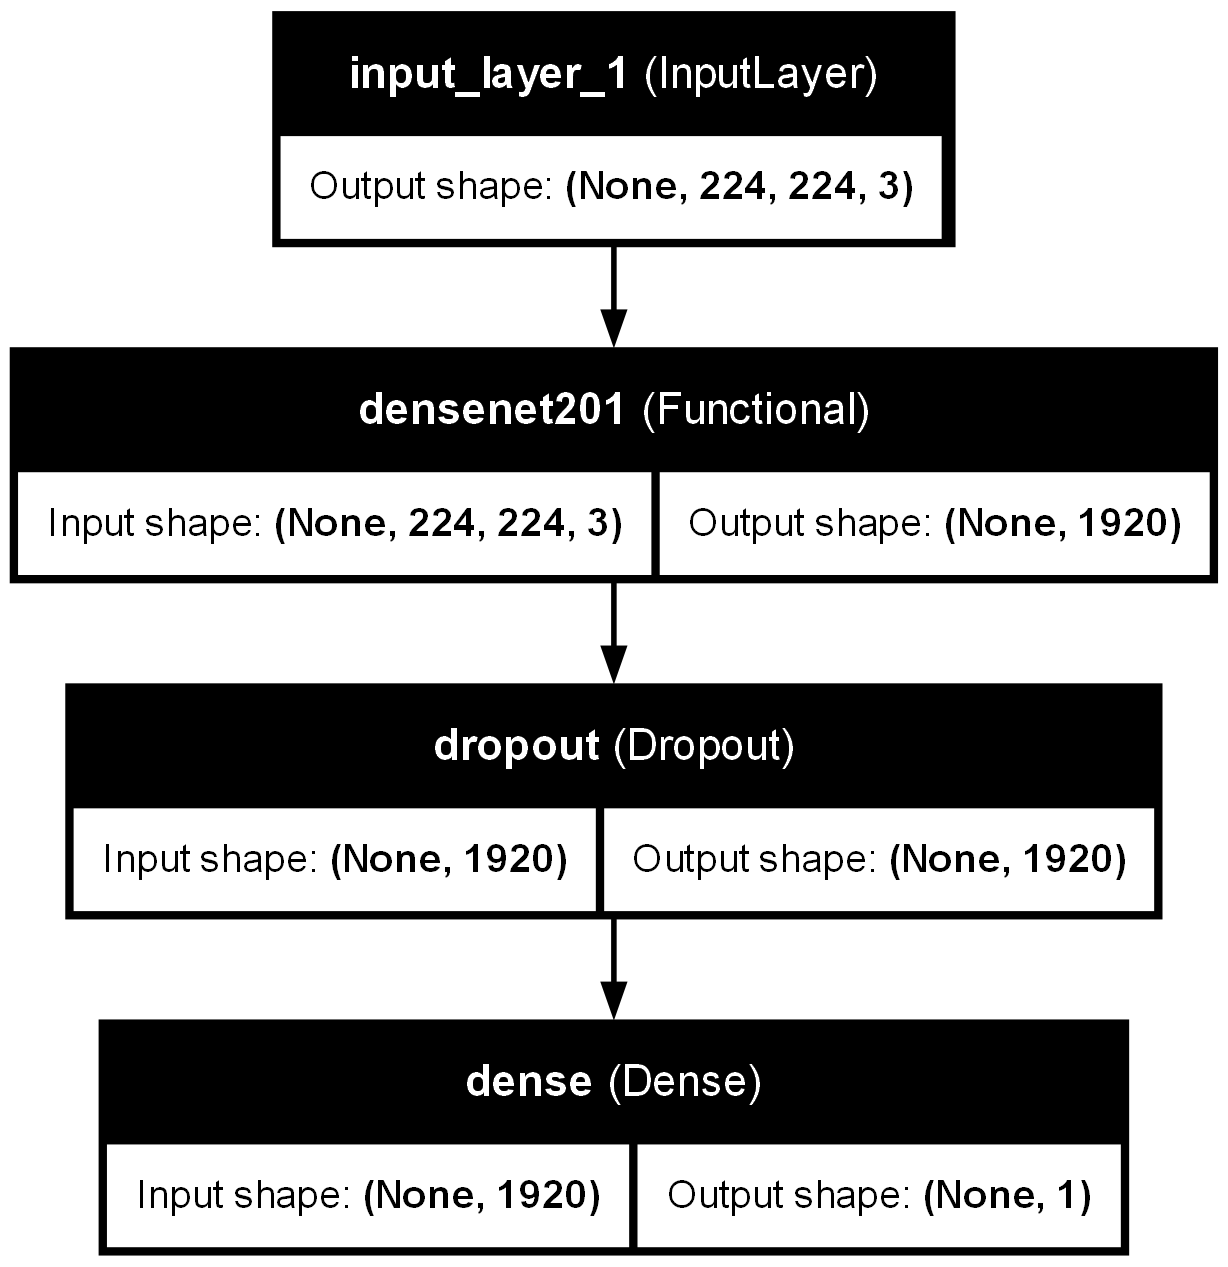

In [29]:
tf.keras.utils.plot_model(
    model,
    to_file=f"../staticdensenet201_pt_imagenet-tüm-çalışma-tipleri-densenet201_pt_imagenet-all-study-types-18323905{model.count_params()}.png",
    show_shapes=True,  # Şekilleri göster
    show_layer_names=True,  # Katman isimlerini göster
)


In [30]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_cohen_kappa",  # Takip edilen metrik
    verbose=1,  # İlerlemeyi terminalde göster
    patience=5,  # İlerleme olmadığında bekleyeceği epoch sayısı
    mode="max",  # Takip edilen metriğin maksimize edilmesi gerektiği
    baseline=0.0,  # Durdurma eşiği (kappa skoru için temel değer)
    restore_best_weights=True,  # En iyi ağırlıkları geri yükle
)


In [31]:
history = model.fit(
    trainset,  # Eğitim veri akışı
    epochs=20,  # Epoch sayısı
    validation_data=validationset,  # Doğrulama veri akışı
    callbacks=[early_stopping],  # Geri çağrılar listesi
)


Epoch 1/20


C:\Users\tosh\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


1048/1048 ━━━━━━━━━━━━━━━━━━━━ 2069s 2s/step - binary_acc: 0.5727 - f1_score: 0.3439 - fn: 931.7798 - fp: 824.9066 - loss: 1.1699 - pr_auc: 0.3558 - precision: 0.3535 - recall: 0.3356 - roc_auc: 0.5179 - tn: 1988.5691 - tp: 453.2307 - val_binary_acc: 0.6385 - val_f1_score: 0.3697 - val_fn: 493.0000 - val_fp: 264.0000 - val_loss: 0.7597 - val_pr_auc: 0.4573 - val_precision: 0.4568 - val_recall: 0.3105 - val_roc_auc: 0.5960 - val_tn: 1115.0000 - val_tp: 222.0000
Epoch 2/20


C:\Users\tosh\AppData\Roaming\Python\Python311\site-packages\keras\src\callbacks\early_stopping.py:155: UserWarning: Early stopping conditioned on metric `val_cohen_kappa` which is not available. Available metrics are: binary_acc,f1_score,fn,fp,loss,pr_auc,precision,recall,roc_auc,tn,tp,val_binary_acc,val_f1_score,val_fn,val_fp,val_loss,val_pr_auc,val_precision,val_recall,val_roc_auc,val_tn,val_tp
  current = self.get_monitor_value(logs)


1048/1048 ━━━━━━━━━━━━━━━━━━━━ 1994s 2s/step - binary_acc: 0.6121 - f1_score: 0.3920 - fn: 888.5577 - fp: 726.7283 - loss: 0.8992 - pr_auc: 0.4254 - precision: 0.4160 - recall: 0.3710 - roc_auc: 0.5883 - tn: 2057.3137 - tp: 527.0687 - val_binary_acc: 0.6996 - val_f1_score: 0.3414 - val_fn: 552.0000 - val_fp: 77.0000 - val_loss: 0.7110 - val_pr_auc: 0.5578 - val_precision: 0.6792 - val_recall: 0.2280 - val_roc_auc: 0.6658 - val_tn: 1302.0000 - val_tp: 163.0000
Epoch 3/20
1048/1048 ━━━━━━━━━━━━━━━━━━━━ 1841s 2s/step - binary_acc: 0.6494 - f1_score: 0.4084 - fn: 842.5596 - fp: 627.6396 - loss: 0.7957 - pr_auc: 0.4686 - precision: 0.4499 - recall: 0.3747 - roc_auc: 0.6233 - tn: 2202.4214 - tp: 524.6454 - val_binary_acc: 0.7116 - val_f1_score: 0.4313 - val_fn: 486.0000 - val_fp: 118.0000 - val_loss: 0.6297 - val_pr_auc: 0.5952 - val_precision: 0.6599 - val_recall: 0.3203 - val_roc_auc: 0.6965 - val_tn: 1261.0000 - val_tp: 229.0000
Epoch 4/20
1048/1048 ━━━━━━━━━━━━━━━━━━━━ 1820s 2s/step - bi

1048/1048 ━━━━━━━━━━━━━━━━━━━━ 1654s 2s/step - binary_acc: 0.7439 - f1_score: 0.5411 - fn: 775.1077 - fp: 292.7703 - loss: 0.5363 - pr_auc: 0.6584 - precision: 0.6763 - recall: 0.4521 - roc_auc: 0.7506 - tn: 2516.3650 - tp: 614.8151 - val_binary_acc: 0.7593 - val_f1_score: 0.5227 - val_fn: 439.0000 - val_fp: 65.0000 - val_loss: 0.5103 - val_pr_auc: 0.7095 - val_precision: 0.8094 - val_recall: 0.3860 - val_roc_auc: 0.7843 - val_tn: 1314.0000 - val_tp: 276.0000
Epoch 19/20
1048/1048 ━━━━━━━━━━━━━━━━━━━━ 1675s 2s/step - binary_acc: 0.7544 - f1_score: 0.5530 - fn: 759.9619 - fp: 276.7350 - loss: 0.5326 - pr_auc: 0.6666 - precision: 0.7016 - recall: 0.4569 - roc_auc: 0.7504 - tn: 2523.4089 - tp: 637.2059 - val_binary_acc: 0.7436 - val_f1_score: 0.4424 - val_fn: 502.0000 - val_fp: 35.0000 - val_loss: 0.5281 - val_pr_auc: 0.7090 - val_precision: 0.8589 - val_recall: 0.2979 - val_roc_auc: 0.7880 - val_tn: 1344.0000 - val_tp: 213.0000
Epoch 20/20
1048/1048 ━━━━━━━━━━━━━━━━━━━━ 1685s 2s/step - b

KeyError: 'cohen_kappa'

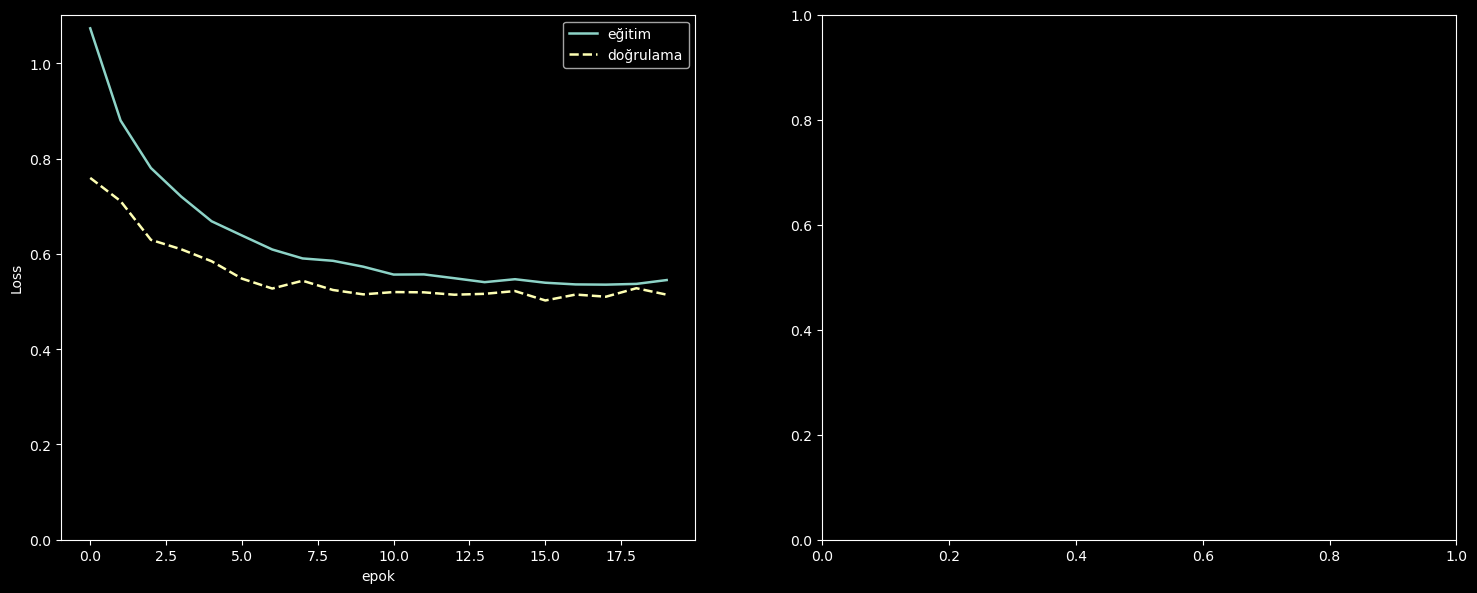

In [32]:
plot_metrics(history)

In [33]:
# Model isimlendirme kuralı: {mimari}-{hangi-çalışma-tipi?}-{parametre-sayısı}.h5
#
# Modelleri yüklemek için:
# model = tf.keras.models.load_model(
#     '../models/densenet201_pt_imagenet-all-study-types-?.h5',
#     custom_objects={'F1Score': F1Score}
# )
# densenet = tf.keras.models.load_model(
#     '../models/densenet201_base.h5',
# )
print(
    f"Kaydediliyor: ../models/densenet201_pt_imagenet-all-study-types-{model.count_params()}.h5"
)
model.save(
    f"../models/densenet201_pt_imagenet-all-study-types-{model.count_params()}.h5"
)
densenet.save("../models/densenet201_base.h5")


Kaydediliyor: ../models/densenet201_pt_imagenet-all-study-types-18323905.h5


In [34]:
# ince ayarlama: taban modelin dondurulması kaldırılır ve tüm model düşük bir öğrenme hızıyla uçtan uca eğitilir
densenet.trainable = True

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        1e-5
    ),  # kastastrofik unutmayı önlemek için küçük bir öğrenme hızı kullanıyoruz
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=METRICS,
)


In [35]:
reduce_lr_on_plateau = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_cohen_kappa",  # İzlenecek metrik
    verbose=1,  # İlerlemeyi terminalde göster
    patience=4,  # İlerleme olmadığında bekleyeceği epoch sayısı
    mode="max",  # Takip edilen metriğin maksimize edilmesi gerektiği
    factor=0.2,  # Öğrenme hızını azaltmak için çarpan
    min_lr=1e-10,  # Öğrenme hızının düşebileceği minimum değer
)


In [36]:
history = model.fit(
    trainset,
    epochs=10,
    validation_data=validationset,
    callbacks=[early_stopping, reduce_lr_on_plateau],
)

Epoch 1/10
1048/1048 ━━━━━━━━━━━━━━━━━━━━ 6222s 6s/step - binary_acc: 0.7128 - f1_score: 0.5141 - fn: 1155.3613 - fp: 655.7864 - loss: 0.6491 - pr_auc: 0.5912 - precision: 0.5963 - recall: 0.4521 - roc_auc: 0.7208 - tn: 3525.3213 - tp: 956.3069 - val_binary_acc: 0.7646 - val_f1_score: 0.5353 - val_fn: 431.0000 - val_fp: 62.0000 - val_loss: 0.5347 - val_pr_auc: 0.7174 - val_precision: 0.8208 - val_recall: 0.3972 - val_roc_auc: 0.7872 - val_tn: 1317.0000 - val_tp: 284.0000 - learning_rate: 1.0000e-05
Epoch 2/10


C:\Users\tosh\AppData\Roaming\Python\Python311\site-packages\keras\src\callbacks\callback_list.py:96: UserWarning: Learning rate reduction is conditioned on metric `val_cohen_kappa` which is not available. Available metrics are: binary_acc,f1_score,fn,fp,loss,pr_auc,precision,recall,roc_auc,tn,tp,val_binary_acc,val_f1_score,val_fn,val_fp,val_loss,val_pr_auc,val_precision,val_recall,val_roc_auc,val_tn,val_tp,learning_rate.
  callback.on_epoch_end(epoch, logs)


1048/1048 ━━━━━━━━━━━━━━━━━━━━ 6390s 6s/step - binary_acc: 0.7397 - f1_score: 0.5640 - fn: 700.7769 - fp: 389.3079 - loss: 0.5628 - pr_auc: 0.6526 - precision: 0.6521 - recall: 0.4976 - roc_auc: 0.7502 - tn: 2402.4985 - tp: 704.9152 - val_binary_acc: 0.7798 - val_f1_score: 0.6237 - val_fn: 333.0000 - val_fp: 128.0000 - val_loss: 0.5004 - val_pr_auc: 0.7327 - val_precision: 0.7490 - val_recall: 0.5343 - val_roc_auc: 0.8013 - val_tn: 1251.0000 - val_tp: 382.0000 - learning_rate: 1.0000e-05
Epoch 3/10
1048/1048 ━━━━━━━━━━━━━━━━━━━━ 5972s 6s/step - binary_acc: 0.7618 - f1_score: 0.5952 - fn: 649.9886 - fp: 354.0810 - loss: 0.5201 - pr_auc: 0.6924 - precision: 0.6773 - recall: 0.5310 - roc_auc: 0.7850 - tn: 2447.5129 - tp: 745.3670 - val_binary_acc: 0.8037 - val_f1_score: 0.6667 - val_fn: 304.0000 - val_fp: 107.0000 - val_loss: 0.4651 - val_pr_auc: 0.7675 - val_precision: 0.7934 - val_recall: 0.5748 - val_roc_auc: 0.8331 - val_tn: 1272.0000 - val_tp: 411.0000 - learning_rate: 1.0000e-05
Epo

In [37]:
# Model isimlendirme kuralı: {mimari}-{hangi-çalışma-tipi?}-{parametre-sayısı}.h5
#
# Modelleri yüklemek için:
# model = tf.keras.models.load_model(
#     '../models/densenet201_pt_imagenet-all-study-types-?.h5',
#     custom_objects={'F1Score': F1Score}
# )
# densenet = tf.keras.models.load_model(
#     '../models/densenet201_base.h5',
# )
print(
    f"Kaydediliyor: ../models/densenet201_pt_imagenet-all-study-types-{model.count_params()}.h5"
)
model.save(
    f"../models/densenet201_pt_imagenet-all-study-types-{model.count_params()}.h5"
)
densenet.save("../models/densenet201_base.h5")


Kaydediliyor: ../models/densenet201_pt_imagenet-all-study-types-18323905.h5


KeyError: 'cohen_kappa'

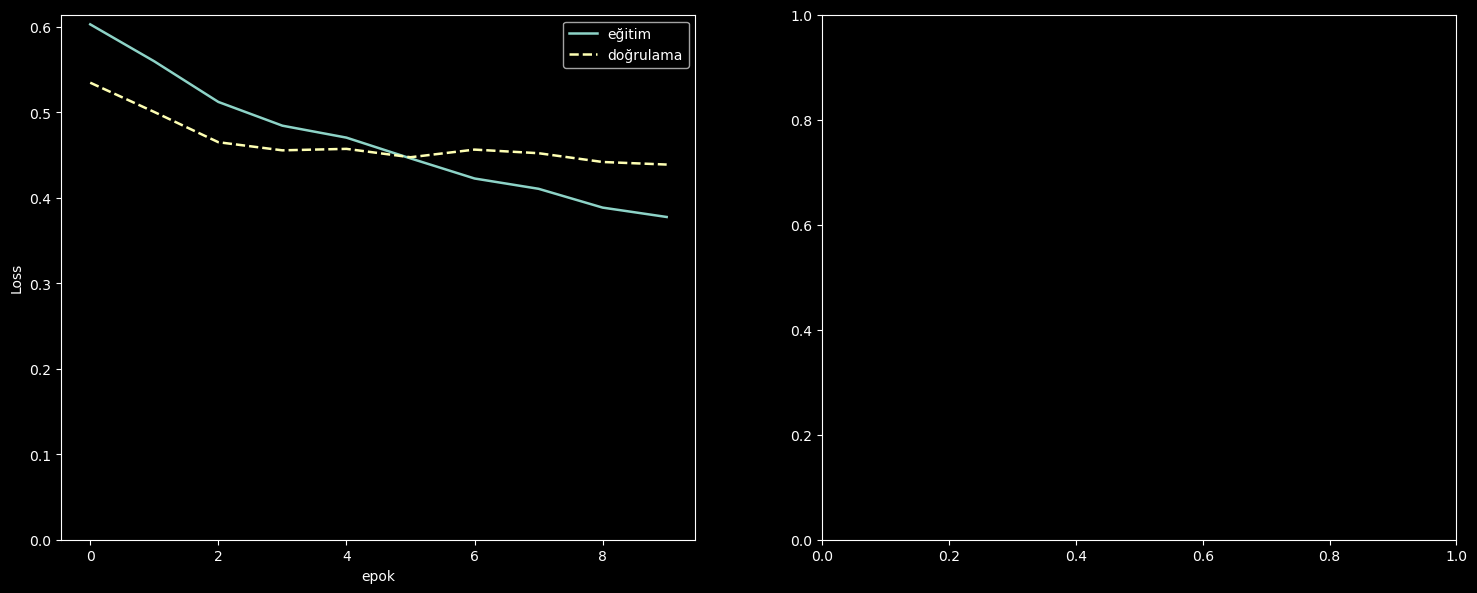

In [38]:
plot_metrics(history)

In [39]:
# Doğrulama modunda model için kayıp değeri ve metrik değerlerini al
evaluation_metrics = model.evaluate(validationset, verbose=1)


262/262 ━━━━━━━━━━━━━━━━━━━━ 362s 1s/step - binary_acc: 0.8041 - f1_score: 0.7022 - fn: 135.0304 - fp: 66.2281 - loss: 0.4626 - pr_auc: 0.8138 - precision: 0.7880 - recall: 0.6336 - roc_auc: 0.8509 - tn: 619.6692 - tp: 235.0266


In [40]:
loss = evaluation_metrics.pop(0)

print(f"val loss    : {loss}")
for metric, score in zip(METRICS, evaluation_metrics):

    print(f"{metric.name + ' ' * (12 - len(metric.name))}: {score}")

val loss    : 0.4438347816467285
tp          : 457.0
fp          : 131.0
tn          : 1248.0
fn          : 258.0
binary_acc  : 0.8142311573028564
precision   : 0.7772108912467957
recall      : 0.6391608119010925
f1_score    : <KerasVariable shape=(), dtype=float32, path=f1_score/f1>
roc_auc     : 0.8547306060791016
pr_auc      : 0.8024196028709412


In [41]:
clean_up(model)
clean_up(densenet)